# Lab 05: Voting Classifier and K-Means Clustering

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

In [2]:
# Load and preprocess dataset for Voting Classifier
inc_data = pd.read_csv('income_evaluation.csv')
inc_data.columns = inc_data.columns.str.strip()

for col in inc_data.select_dtypes(include='object').columns:
    inc_data[col] = LabelEncoder().fit_transform(inc_data[col].str.strip())

X = inc_data.drop('income', axis=1)
y = inc_data['income']

X_scaled = StandardScaler().fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)
some_digit = X_test[0]

In [3]:
log_clf = LogisticRegression()
rnd_clf = RandomForestClassifier(random_state=42)
svm_clf = SVC()

voting_clf = VotingClassifier(
    estimators=[('lr', log_clf), ('rf', rnd_clf), ('svc', svm_clf)],
    voting='hard'
)
voting_clf.fit(X_train, y_train)
print(voting_clf.predict([some_digit]))

[1]


In [4]:
for clf in (log_clf, rnd_clf, svm_clf, voting_clf):
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    print(clf.__class__.__name__, accuracy_score(y_test, y_pred))

LogisticRegression 0.8336501901140685
RandomForestClassifier 0.8602661596958175
SVC 0.8545627376425855
VotingClassifier 0.8583650190114068


## Part 2: K-Means Clustering (Slide Implementation)

In [5]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Step 1: Load the dataset
data = pd.read_csv("mushroomss.csv")

# Display first few rows
print("Dataset Preview:")
print(data.head())

# Step 2: Check for missing values
print("\nMissing Values in Each Column:")
print(data.isnull().sum())

Dataset Preview:
  cap-shape cap-surface cap-color bruises odor gill-attachment gill-spacing gill-size gill-color stalk-shape stalk-root stalk-surface-above-ring stalk-surface-below-ring stalk-color-above-ring stalk-color-below-ring veil-type veil-color ring-number ring-type spore-print-color population habitat
0         x           s         n       t    p               f            c         n          k           e          e                        s                        s                      w                      w         p          w           o         p                 k          s       u
1         x           s         y       t    a               f            c         b          k           e          c                        s                        s                      w                      w         p          w           o         p                 n          n       g
2         b           s         w       t    l               f            c         b          

In [6]:
# Step 3: Encode categorical features (if any)
label_encoders = {}
for column in data.columns:
    if data[column].dtype == 'object':
        le = LabelEncoder()
        data[column] = le.fit_transform(data[column])
        label_encoders[column] = le

# Step 4: Apply K-Means Clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
data['Cluster'] = kmeans.fit_predict(data)

# Step 5: Display cluster centers and counts
print("\nCluster Centers:\n", kmeans.cluster_centers_)
print("\nCluster Counts:\n", data['Cluster'].value_counts())


Cluster Centers:
 [[3.34323713e+00 1.67543860e+00 3.75947934e+00 7.08545557e-01
  4.33786078e+00 9.42840973e-01 1.35257499e-01 1.29315224e-01
  8.04612337e+00 5.86021505e-01 1.16808149e+00 1.80249010e+00
  1.85398981e+00 5.71646859e+00 5.66666667e+00 0.00000000e+00
  1.92416525e+00 1.09847199e+00 3.48613469e+00 3.05744199e+00
  3.80871534e+00 1.02263724e+00]
 [3.30393199e+00 2.46227418e+00 2.97662062e+00 5.63230606e-02
  5.61211477e+00 1.00000000e+00 2.55047821e-02 9.18172157e-01
  1.12646121e-01 9.18172157e-01 5.31349628e-03 1.52816153e+00
  1.52816153e+00 6.41339001e+00 6.41339001e+00 0.00000000e+00
  2.00000000e+00 1.08182784e+00 1.23273114e-01 6.98937301e+00
  3.80871413e+00 2.17959617e+00]
 [3.38515510e+00 1.58530281e+00 6.53914328e+00 2.82865583e-01
  2.87296898e+00 9.97045790e-01 2.90251108e-01 1.20753323e-01
  3.85339734e+00 2.98744461e-01 1.80132939e+00 1.31093058e+00
  1.32939439e+00 5.53175775e+00 5.53175775e+00 0.00000000e+00
  1.99556869e+00 1.02289513e+00 2.24076809e+00 

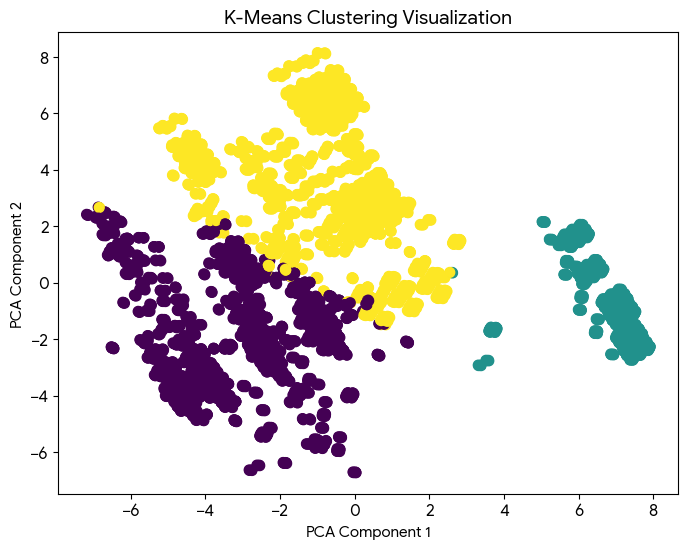

In [7]:
# Step 6: Visualize clusters using PCA (2D)
pca = PCA(n_components=2)
reduced_data = pca.fit_transform(data.drop('Cluster', axis=1))

plt.figure(figsize=(8, 6))
plt.scatter(reduced_data[:, 0], reduced_data[:, 1], c=data['Cluster'], cmap='viridis', s=50)
plt.title('K-Means Clustering Visualization')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.show()

## Part 3: K-Means Exercise (Activity 3 - Mall_Customers)

### 1. Load and Display the Dataset

In [8]:
mall_df = pd.read_csv('Mall_Customers.csv')
print(f"Dataset Shape: {mall_df.shape}")
mall_df.head(10)

Dataset Shape: (200, 5)


### 2. Elbow Method to Find the Best k

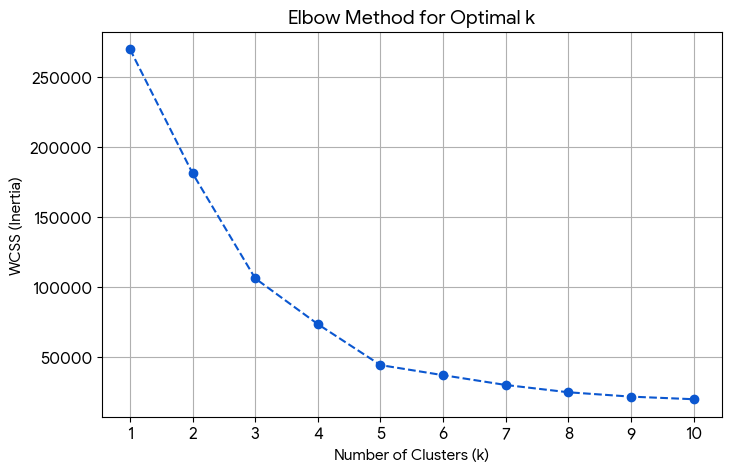

In [9]:
X_mall = mall_df[['Annual Income (k$)', 'Spending Score (1-100)']].values

wcss = []
K_range = range(1, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_mall)
    wcss.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, wcss, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(K_range)
plt.grid(True)
plt.show()

The elbow bends sharply at **k = 5**, so 5 is the optimal number of clusters.

### 3. Apply K-Means and DBSCAN (Annual Income vs Spending Score)

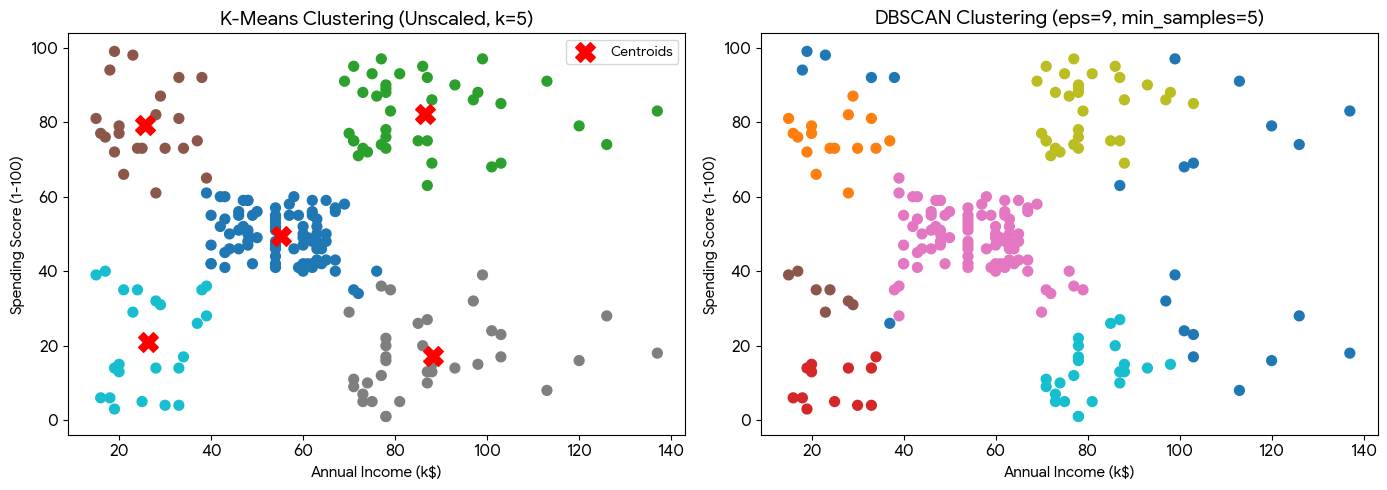

In [10]:
from sklearn.cluster import DBSCAN

# K-Means with k=5
kmeans_unscaled = KMeans(n_clusters=5, random_state=42, n_init=10)
y_kmeans_unscaled = kmeans_unscaled.fit_predict(X_mall)

# DBSCAN
dbscan = DBSCAN(eps=9, min_samples=5)
y_dbscan = dbscan.fit_predict(X_mall)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# K-Means Plot
axes[0].scatter(X_mall[:, 0], X_mall[:, 1], c=y_kmeans_unscaled, cmap='tab10', s=50)
axes[0].scatter(kmeans_unscaled.cluster_centers_[:, 0], kmeans_unscaled.cluster_centers_[:, 1],
                s=200, c='red', marker='X', label='Centroids')
axes[0].set_title('K-Means Clustering (Unscaled, k=5)')
axes[0].set_xlabel('Annual Income (k$)')
axes[0].set_ylabel('Spending Score (1-100)')
axes[0].legend()

# DBSCAN Plot
axes[1].scatter(X_mall[:, 0], X_mall[:, 1], c=y_dbscan, cmap='tab10', s=50)
axes[1].set_title('DBSCAN Clustering (eps=9, min_samples=5)')
axes[1].set_xlabel('Annual Income (k$)')
axes[1].set_ylabel('Spending Score (1-100)')

plt.tight_layout()
plt.show()

### 4. Scale Features with StandardScaler and Re-run K-Means

Cluster Assignment Comparison (Unscaled vs Scaled):
Scaled     0   1   2   3   4
Unscaled                    
0         81   0   0   0   0
1          0  39   0   0   0
2          0   0  22   0   0
3          0   0   0  35   0
4          0   0   0   0  23


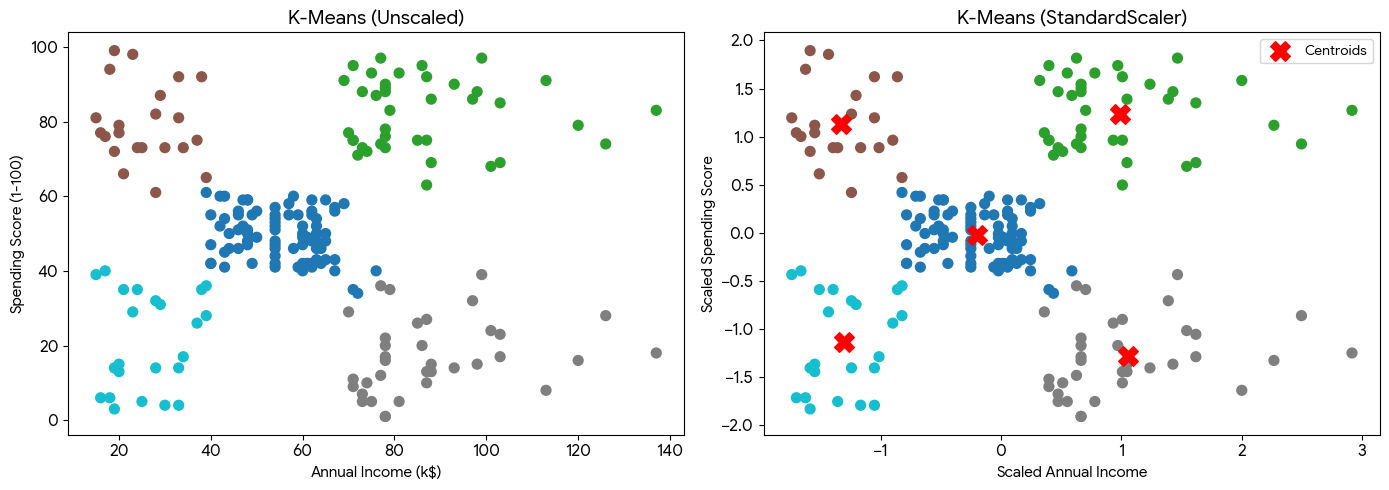

In [11]:
scaler = StandardScaler()
X_mall_scaled = scaler.fit_transform(X_mall)

kmeans_scaled = KMeans(n_clusters=5, random_state=42, n_init=10)
y_kmeans_scaled = kmeans_scaled.fit_predict(X_mall_scaled)

# Check if cluster assignments changed
comparison = pd.crosstab(y_kmeans_unscaled, y_kmeans_scaled, rownames=['Unscaled'], colnames=['Scaled'])
print("Cluster Assignment Comparison (Unscaled vs Scaled):")
print(comparison)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(X_mall[:, 0], X_mall[:, 1], c=y_kmeans_unscaled, cmap='tab10', s=50)
axes[0].set_title('K-Means (Unscaled)')
axes[0].set_xlabel('Annual Income (k$)')
axes[0].set_ylabel('Spending Score (1-100)')

axes[1].scatter(X_mall_scaled[:, 0], X_mall_scaled[:, 1], c=y_kmeans_scaled, cmap='tab10', s=50)
axes[1].scatter(kmeans_scaled.cluster_centers_[:, 0], kmeans_scaled.cluster_centers_[:, 1],
                s=200, c='red', marker='X', label='Centroids')
axes[1].set_title('K-Means (StandardScaler)')
axes[1].set_xlabel('Scaled Annual Income')
axes[1].set_ylabel('Scaled Spending Score')
axes[1].legend()

plt.tight_layout()
plt.show()

### 6. Effect of Adding a Random Feature (`LuckyNumber` 0–100)

Cross-tabulation of Original Clusters vs Clusters with LuckyNumber:
With LuckyNumber   0   1   2   3   4
Original                            
0                  0  39   0  40   2
1                 32   7   0   0   0
2                  0  18   0   4   0
3                  0   0   0   2  33
4                  0   0  20   3   0


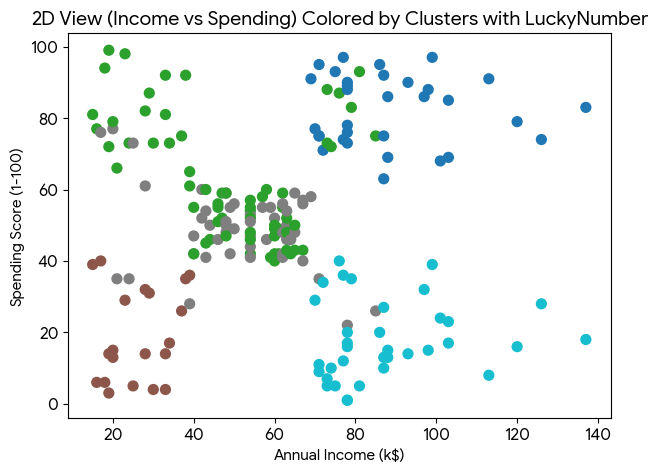

In [12]:
np.random.seed(42)
mall_df['LuckyNumber'] = np.random.randint(0, 101, size=len(mall_df))

X_with_lucky = mall_df[['Annual Income (k$)', 'Spending Score (1-100)', 'LuckyNumber']].values
X_with_lucky_scaled = StandardScaler().fit_transform(X_with_lucky)

kmeans_lucky = KMeans(n_clusters=5, random_state=42, n_init=10)
y_kmeans_lucky = kmeans_lucky.fit_predict(X_with_lucky_scaled)

print("Cross-tabulation of Original Clusters vs Clusters with LuckyNumber:")
print(pd.crosstab(y_kmeans_scaled, y_kmeans_lucky, rownames=['Original'], colnames=['With LuckyNumber']))

plt.figure(figsize=(7, 5))
plt.scatter(X_mall[:, 0], X_mall[:, 1], c=y_kmeans_lucky, cmap='tab10', s=50)
plt.title('2D View (Income vs Spending) Colored by Clusters with LuckyNumber')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()